In [1]:
import argparse
import time
from pathlib import Path

from joblib import Parallel, delayed
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from skimage.feature import hog
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from torch.utils.data import Subset
from torchvision.datasets import EuroSAT



In [2]:
def parse_args():
    parser = argparse.ArgumentParser(
        description="Compare classical ML models on EuroSAT RGB land-cover images."
    )
    parser.add_argument(
        "--data-dir", default="./data",
        help="Directory where EuroSAT will be downloaded/stored."
    )
    parser.add_argument(
        "--per-class", type=int, default=1000,
        help="Maximum images per class. Use 0 to use the full dataset."
    )
    parser.add_argument("--test-size", type=float, default=0.2)
    parser.add_argument("--random-state", type=int, default=42)
    parser.add_argument("--output-dir", default="./outputs")
    
    args, _ = parser.parse_known_args()
    return args


In [3]:
def extract_single_feature(img_pil):
    """
    Extracts concatenated spectral and spatial features:
    - 32-bin color histogram per RGB channel (96 dims)
    - Channel statistical moments: Mean, Std (6 dims)
    - Grayscale HOG descriptor (1764 dims)
    Total = 1866 dimensions
    """
    img = np.asarray(img_pil, dtype=np.float32) / 255.0

    # 1. Spectral features: Histograms + Statistical Moments
    ch_hists = [
        np.histogram(img[:, :, c], bins=32, range=(0.0, 1.0), density=True)[0]
        for c in range(3)
    ]
    ch_means = np.mean(img, axis=(0, 1))
    ch_stds = np.std(img, axis=(0, 1))
    
    spectral_feat = np.hstack([*ch_hists, ch_means, ch_stds])

    gray = (
        0.299 * img[:, :, 0]
        + 0.587 * img[:, :, 1]
        + 0.114 * img[:, :, 2]
    )
    hog_feat = hog(
        gray,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        feature_vector=True,
    )

    return np.hstack([spectral_feat, hog_feat]).astype(np.float32)


In [4]:
def load_dataset_parallel(data_dir, per_class, random_state):
    dataset = EuroSAT(root=data_dir, download=True)
    targets = np.asarray(dataset.targets)
    class_names = dataset.classes

    if per_class and per_class > 0:
        rng = np.random.default_rng(random_state)
        chosen = []
        for class_id in range(len(class_names)):
            class_indices = np.flatnonzero(targets == class_id)
            count = min(per_class, len(class_indices))
            chosen.extend(rng.choice(class_indices, size=count, replace=False))
        indices = np.asarray(sorted(chosen))
        dataset = Subset(dataset, indices.tolist())
        labels = targets[indices]
    else:
        labels = targets

    print(f"Extracting features from {len(dataset)} images across all available CPU cores...")
    start = time.perf_counter()

    features = Parallel(n_jobs=-1, batch_size=64)(
        delayed(extract_single_feature)(dataset[i][0]) for i in range(len(dataset))
    )
    
    extraction_seconds = time.perf_counter() - start
    return np.vstack(features), labels, class_names, extraction_seconds


In [5]:
def main():
    args = parse_args()
    output_dir = Path(args.output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    X, y, class_names, extraction_seconds = load_dataset_parallel(
        args.data_dir, args.per_class, args.random_state
    )

    print(f"Samples: {len(y)}")
    print(f"Feature vector dimensionality: {X.shape[1]}")
    print(f"Classes: {class_names}")
    print(f"Extraction wall-clock time: {extraction_seconds:.2f} seconds")

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=args.test_size,
        random_state=args.random_state,
        stratify=y,
    )

    models = {
        "Random Forest": RandomForestClassifier(
            n_estimators=200, random_state=args.random_state, n_jobs=-1
        ),
        "SVM (RBF)": make_pipeline(
            StandardScaler(),
            SVC(kernel="rbf", C=10.0, gamma="scale", random_state=args.random_state)
        ),
        "KNN (k=5)": make_pipeline(
            StandardScaler(),
            KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
        ),
    }

    rows = []
    fitted = {}

    for name, model in models.items():
        t0 = time.perf_counter()
        model.fit(X_train, y_train)
        train_seconds = time.perf_counter() - t0
        
        preds = model.predict(X_test)
        fitted[name] = model

        acc = accuracy_score(y_test, preds)
        macro_f1 = f1_score(y_test, preds, average="macro")

        rows.append({
            "Model": name,
            "Accuracy": acc,
            "Macro F1": macro_f1,
            "Training Time (s)": train_seconds,
        })

        print(f"\n=================== {name} ===================")
        print(f"Train Time: {train_seconds:.2f}s | Acc: {acc:.4f} | F1: {macro_f1:.4f}")
        print(classification_report(
            y_test, preds, labels=np.arange(len(class_names)),
            target_names=class_names, zero_division=0, digits=3
        ))

    results = pd.DataFrame(rows).sort_values("Macro F1", ascending=False)
    results.to_csv(output_dir / "model_results.csv", index=False)
    
    print("\nBenchmark Summary:")
    print(results.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

    # Plot metrics
    ax = results.set_index("Model")[["Accuracy", "Macro F1"]].plot(
        kind="bar", ylim=(0, 1.05), figsize=(8, 4.5), rot=0, grid=True
    )
    ax.set_ylabel("Score")
    ax.set_title("EuroSAT Benchmark: Classical ML on Spectral + HOG")
    plt.tight_layout()
    plt.savefig(output_dir / "model_comparison.png", dpi=200)
    plt.show()
    plt.close()

    best_name = results.iloc[0]["Model"]
    fig, ax = plt.subplots(figsize=(9, 9))
    ConfusionMatrixDisplay.from_estimator(
        fitted[best_name],
        X_test,
        y_test,
        labels=np.arange(len(class_names)),
        display_labels=class_names,
        xticks_rotation=45,
        cmap="Blues",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(f"Confusion Matrix: {best_name}")
    plt.tight_layout()
    plt.savefig(output_dir / "confusion_matrix.png", dpi=200)
    plt.show()
    plt.close()
    print(f"\nArtifacts successfully written to: {output_dir.resolve()}")


Extracting features from 10000 images across all available CPU cores...
Samples: 10000
Feature vector dimensionality: 1866
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Extraction wall-clock time: 1.82 seconds

=================== Random Forest ===================
Train Time: 1.85s | Acc: 0.7860 | F1: 0.7811
                      precision    recall  f1-score   support

          AnnualCrop      0.770     0.855     0.810       200
              Forest      0.886     0.935     0.910       200
HerbaceousVegetation      0.755     0.615     0.678       200
             Highway      0.723     0.575     0.641       200
          Industrial      0.786     0.935     0.854       200
             Pasture      0.694     0.815     0.749       200
       PermanentCrop      0.742     0.605     0.667       200
         Residential      0.824     0.935     0.876       200
               River      0.696

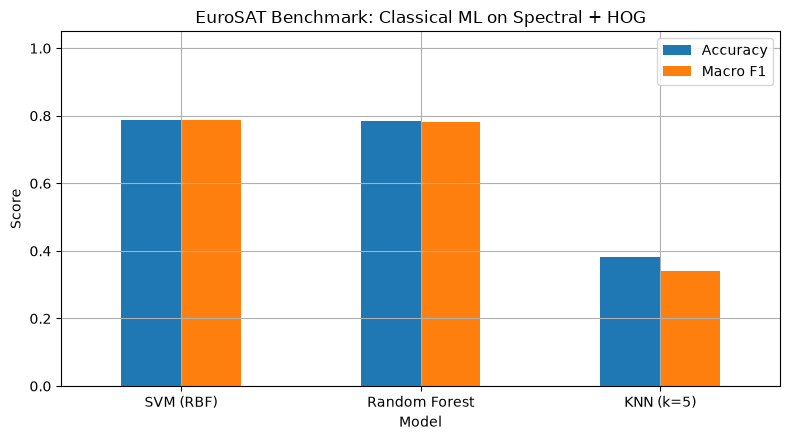

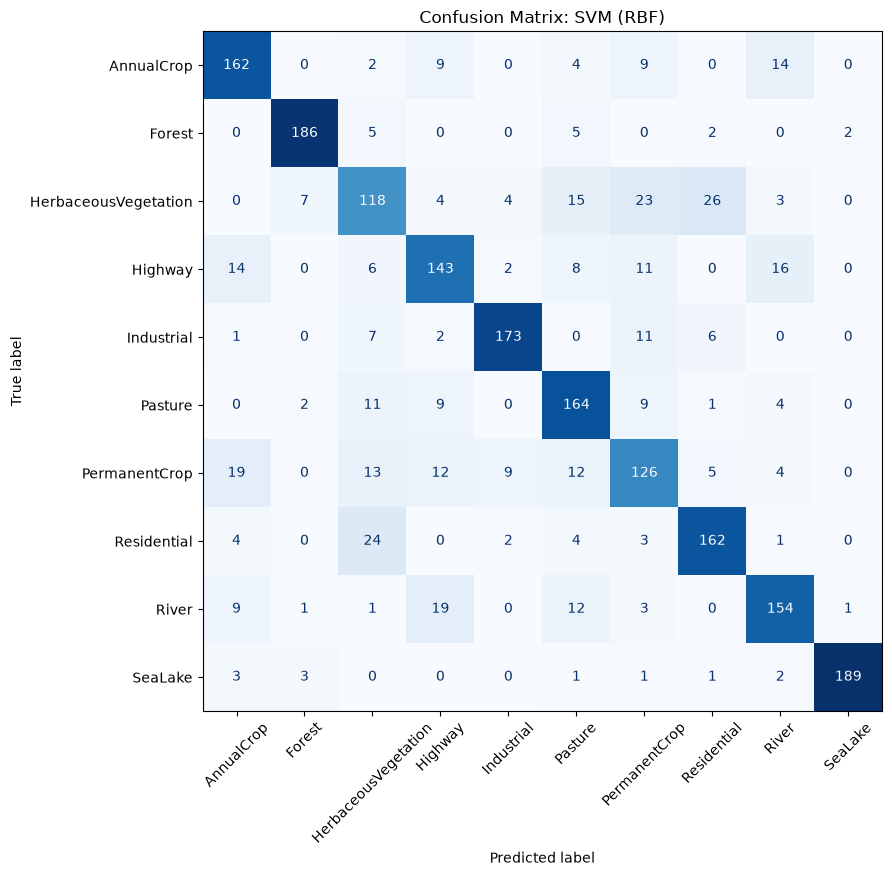


Artifacts successfully written to: C:\NUIST\Machine Learning\outputs


In [7]:
if __name__ == "__main__":
    main()